Matplotlib is building the font cache; this may take a moment.


Primary model (fixed before testing): HC start=hand
train 3,571 songs | test 893 songs
Majority bin in train: (40.0, 60.0]  (34.4% of train, 32.7% of test)
                                            test_accuracy  acc_ci_lo  acc_ci_hi  test_log_loss  ll_ci_lo  ll_ci_hi  within_one_bin  mean_abs_bin_error  joint_loglik_per_song
model                                                                                                                                                                        
HC + BIC                                           0.4434     0.4110     0.4759         1.3298    1.2886    1.3702          0.8387              0.7503               -13.2685
HC start=hand                                      0.4434     0.4099     0.4759         1.2984    1.2559    1.3401          0.8477              0.7357               -13.2444
Hand-designed                                      0.4345     0.4009     0.4658         1.3181    1.2744    1.3612          0.8376              0.75

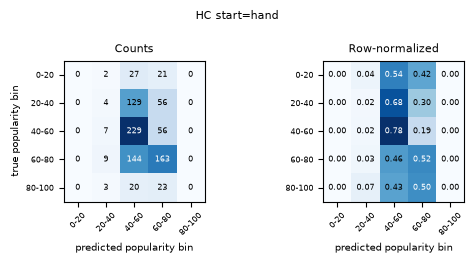

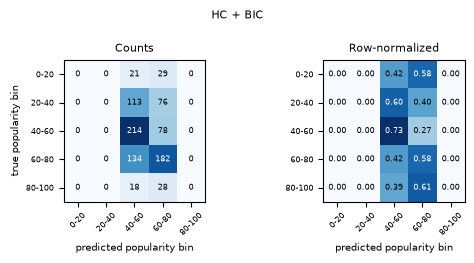

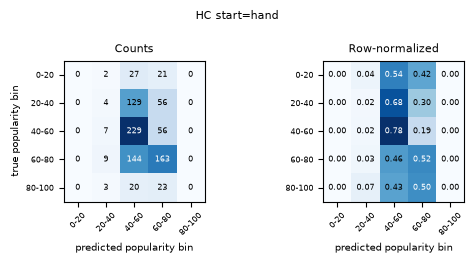

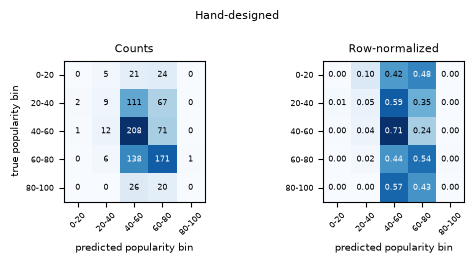

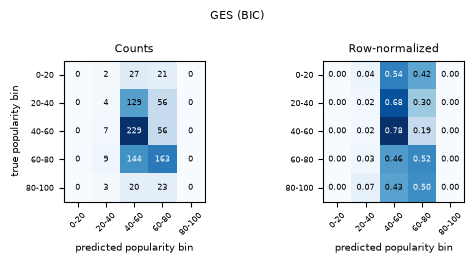

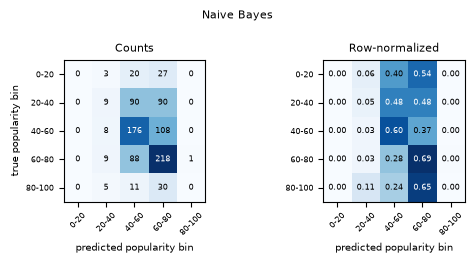


How often each model PREDICTS each bin (test):
                HC + BIC  HC start=hand  Hand-designed  GES (BIC)  Naive Bayes  Baseline: prior only (always majority bin)
(-0.001, 20.0]         0              0              3          0            0                                           0
(20.0, 40.0]           0             25             32         25           34                                           0
(40.0, 60.0]         500            549            504        549          385                                         893
(60.0, 80.0]         393            319            353        319          473                                           0
(80.0, 100.0]          0              0              1          0            1                                           0
True test distribution: [50, 189, 292, 316, 46]


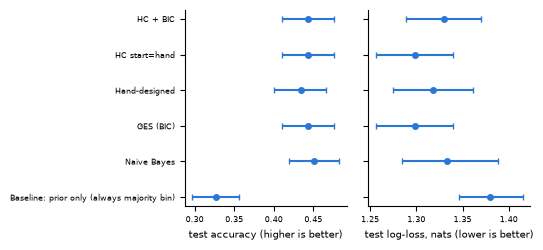

In [1]:
# %% [markdown]
# # Final evaluation on the held-out test set
#
# This is the FIRST and ONLY place `test.csv` is used for scoring. Nothing here
# refits, retunes or reselects: we load the tuned, frozen models from
# `models/parameter_config.json` and score them once. The primary model was fixed
# by training-set CV before this notebook existed, so it is not chosen from test results.
#
# Run from the repository root with `PYTHONHASHSEED=0`.
# Paste each `# %%` block into a notebook cell (or open with jupytext).

# %% imports and configuration
import json
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from bn_structures import load_split
from parameter_inference import (
    TARGET, SEED, fit_parameters, load_fitted_model, popularity_log_probabilities,
)

ROOT = Path.cwd()
assert (ROOT / "models/parameter_config.json").is_file(), "Run from the repository root"
FIG_DIR = ROOT / "figures/evaluation"; FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "models"

with open(MODEL_DIR / "parameter_config.json") as f:
    config = json.load(f)

# Popularity bins in ORDER (low -> high). Keep this order for every table and plot.
ORDER = ["(-0.001, 20.0]", "(20.0, 40.0]", "(40.0, 60.0]", "(60.0, 80.0]", "(80.0, 100.0]"]
assert list(config["state_names"][TARGET]) == ORDER, "State order changed; fix ORDER"
PRIMARY = config["primary_model_id"]
print("Primary model (fixed before testing):", PRIMARY)

# %% load data and models
train, test = load_split()
print(f"train {len(train):,} songs | test {len(test):,} songs")
X_test = test.drop(columns=TARGET)
y = pd.Categorical(test[TARGET], categories=ORDER).codes
assert (y >= 0).all(), "Unknown popularity state in test set"

models = {name: load_fitted_model(ROOT / spec["model_path"])
          for name, spec in config["per_structure"].items()}

# Baseline: independent variables (empty graph), fit on TRAIN only, with light smoothing.
# Its P(popularity | features) is just the training marginal, so its argmax is the
# always-majority-class prediction and its log-loss is the "prior only" log-loss.
BASELINE = "Baseline: prior only (always majority bin)"
models[BASELINE] = fit_parameters(train, "Empty graph (prior only)", "BDeu", 1)

majority_bin = train[TARGET].mode()[0]
print(f"Majority bin in train: {majority_bin}  "
      f"({(train[TARGET] == majority_bin).mean():.1%} of train, "
      f"{(test[TARGET] == majority_bin).mean():.1%} of test)")

# %% exact predictive distributions P(popularity | the other nine variables)
LOGP = {name: popularity_log_probabilities(m, X_test) for name, m in models.items()}
for name, lp in LOGP.items():
    assert np.isfinite(lp).all(), f"{name}: undefined or zero-probability rows on test"
    assert np.allclose(np.exp(lp).sum(1), 1), f"{name}: posteriors not normalized"


def joint_loglik(model, df):
    """Per-song log P(all 10 variables) under the model (sum of log CPT entries)."""
    total = np.zeros(len(df))
    for cpd in model.get_cpds():
        idx = []
        for v in cpd.variables:
            codes = pd.Categorical(df[v], categories=cpd.state_names[v]).codes
            assert (codes >= 0).all(), f"unknown state in {v}"
            idx.append(codes)
        total += np.log(cpd.values[tuple(idx)])
    return total


JOINT = {name: joint_loglik(m, test) for name, m in models.items()}

# %% metrics, with bootstrap confidence intervals
N = len(y)
rng = np.random.default_rng(SEED)
B = 2000
BOOT = rng.integers(0, N, size=(B, N))          # same resamples for every model -> paired comparisons


def per_song(lp):
    pred = lp.argmax(1)
    return {"correct": (pred == y).astype(float),
            "nll": -lp[np.arange(N), y],
            "within1": (np.abs(pred - y) <= 1).astype(float),
            "bin_err": np.abs(pred - y).astype(float)}


PS = {name: per_song(lp) for name, lp in LOGP.items()}


def ci(values_by_song):
    boot = values_by_song[BOOT].mean(1)
    return values_by_song.mean(), *np.percentile(boot, [2.5, 97.5])


rows = []
for name, ps in PS.items():
    acc, acc_lo, acc_hi = ci(ps["correct"])
    nll, nll_lo, nll_hi = ci(ps["nll"])
    rows.append({"model": name,
                 "test_accuracy": acc, "acc_ci_lo": acc_lo, "acc_ci_hi": acc_hi,
                 "test_log_loss": nll, "ll_ci_lo": nll_lo, "ll_ci_hi": nll_hi,
                 "within_one_bin": ps["within1"].mean(),
                 "mean_abs_bin_error": ps["bin_err"].mean(),
                 "joint_loglik_per_song": JOINT[name].mean()})
results = pd.DataFrame(rows).set_index("model")
results.to_csv(MODEL_DIR / "test_results.csv")
print(results.round(4).to_string())

# %% paired differences: is each model really better than the baseline / the primary model?
paired = []
for name in PS:
    if name == BASELINE:
        continue
    for ref in [BASELINE, PRIMARY]:
        if name == ref:
            continue
        d_acc = PS[name]["correct"] - PS[ref]["correct"]
        d_nll = PS[name]["nll"] - PS[ref]["nll"]            # negative = better than ref
        b_acc, b_nll = d_acc[BOOT].mean(1), d_nll[BOOT].mean(1)
        paired.append({"model": name, "vs": ref,
                       "d_accuracy": d_acc.mean(), "d_acc_lo": np.percentile(b_acc, 2.5), "d_acc_hi": np.percentile(b_acc, 97.5),
                       "d_log_loss": d_nll.mean(), "d_ll_lo": np.percentile(b_nll, 2.5), "d_ll_hi": np.percentile(b_nll, 97.5)})
paired = pd.DataFrame(paired)
paired.to_csv(MODEL_DIR / "test_paired_differences.csv", index=False)
print(paired.round(4).to_string(index=False))
print("\nAn interval that excludes 0 means the difference is distinguishable from noise on this test set.")

# %% generalization gap: training-CV (parameter stage) vs. test
cv = {n: s for n, s in config["per_structure"].items()}
gap = pd.DataFrame({
    "cv_log_loss": {n: cv[n]["cv_log_loss"] for n in cv},
    "test_log_loss": {n: results.loc[n, "test_log_loss"] for n in cv},
    "cv_accuracy": {n: cv[n]["cv_accuracy"] for n in cv},
    "test_accuracy": {n: results.loc[n, "test_accuracy"] for n in cv},
})
gap["log_loss_gap"] = gap.test_log_loss - gap.cv_log_loss
print(gap.round(4).to_string())
print("Note: CV graphs were learned on all of train, so CV numbers are slightly optimistic.")

# %% confusion matrices (counts and row-normalized) for the primary model
def plot_confusion(name, path):
    pred = LOGP[name].argmax(1)
    cm = confusion_matrix(y, pred, labels=range(5))
    cm_row = cm / cm.sum(1, keepdims=True).clip(min=1)
    short = ["0-20", "20-40", "40-60", "60-80", "80-100"]
    fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.6))
    for ax, mat, title, fmt in [(axes[0], cm, "Counts", "{:d}"), (axes[1], cm_row, "Row-normalized", "{:.2f}")]:
        ax.imshow(mat, cmap="Blues")
        for i in range(5):
            for j in range(5):
                v = mat[i, j]
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=6,
                        color="white" if v > mat.max() * 0.6 else "black")
        ax.set_xticks(range(5), short, fontsize=6, rotation=45)
        ax.set_yticks(range(5), short, fontsize=6)
        ax.set_xlabel("predicted popularity bin", fontsize=7)
        ax.set_title(title, fontsize=8)
    axes[0].set_ylabel("true popularity bin", fontsize=7)
    fig.suptitle(name, fontsize=8)
    plt.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight"); plt.show()
    return cm


cm_primary = plot_confusion(PRIMARY, FIG_DIR / "confusion_primary.png")
for name in config["per_structure"]:                      # the rest go to an appendix
    plot_confusion(name, FIG_DIR / f"confusion_{name.replace(' ', '_').replace('+', 'plus').replace('(', '').replace(')', '').replace('=', '-')}.png")

pred_dist = pd.DataFrame({name: np.bincount(LOGP[name].argmax(1), minlength=5) for name in LOGP}, index=ORDER)
print("\nHow often each model PREDICTS each bin (test):")
print(pred_dist.to_string())
print("True test distribution:", np.bincount(y, minlength=5).tolist())

# %% report figure: accuracy and log-loss with 95% CIs
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.6), sharey=True)
names = list(results.index)[::-1]
ypos = np.arange(len(names))
for ax, col, lo, hi, label in [(axes[0], "test_accuracy", "acc_ci_lo", "acc_ci_hi", "test accuracy (higher is better)"),
                               (axes[1], "test_log_loss", "ll_ci_lo", "ll_ci_hi", "test log-loss, nats (lower is better)")]:
    v = results.loc[names, col].to_numpy()
    err = np.vstack([v - results.loc[names, lo].to_numpy(), results.loc[names, hi].to_numpy() - v])
    ax.errorbar(v, ypos, xerr=err, fmt="o", ms=4, capsize=2, color="#2a78d6")
    ax.set_xlabel(label, fontsize=7); ax.tick_params(labelsize=6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(ypos, names, fontsize=6)
plt.tight_layout(); fig.savefig(FIG_DIR / "test_metrics.png", dpi=200, bbox_inches="tight"); plt.show()

# %% [markdown]
# ## Writing it up (checklist)
# * Report accuracy, test log-loss, and the confusion matrix for the **primary** model; the others go in a table.
# * Quote the always-majority baseline on the TEST set (its share of test, printed above), not the training 34.4%.
# * Use the bootstrap intervals. With ~900 test songs, an accuracy CI is about +/-3 points, so a 1-point gap
#   between two models is noise. Say so.
# * "Test log-likelihood" here is the conditional log P(popularity | other 9 variables) = -test_log_loss per song.
#   `joint_loglik_per_song` is the log-probability of the whole 10-variable song and is a separate quantity.
# * Do not change the primary model or retune anything after seeing these numbers.